In [1]:
# ✅ Upgrade pip quietly
!python -m pip install --upgrade pip -q

# ✅ Remove incompatible torch/vision/audio first
!pip uninstall -y torch torchvision torchaudio -q

# ✅ Install matching Torch stack (CUDA 12.1 example)
!pip install -q --index-url https://download.pytorch.org/whl/cu121 \
  torch==2.3.1 \
  torchvision==0.18.1 \
  torchaudio==2.3.1

# ✅ Core HF + LoRA stack (compatible with transformers 4.51.0)
!pip install -q -U \
  transformers==4.51.0 \
  accelerate==0.34.2 \
  datasets==2.20.0 \
  peft==0.11.1 \
  trl==0.9.6 \
  sentencepiece==0.1.99 \
  safetensors==0.4.3

# ✅ Optional helpers with fixed hub version
!pip install -q -U \
  huggingface_hub==0.30.0 \
  hf_transfer==0.1.6 \
  wandb==0.17.6 \
  scipy==1.13.1 \
  matplotlib==3.9.0

In [2]:
!transformers-cli env


Copy-and-paste the text below in your GitHub issue and FILL OUT the two last points.

- `transformers` version: 4.51.0
- Platform: Linux-6.8.0-52-generic-x86_64-with-glibc2.35
- Python version: 3.11.11
- Huggingface_hub version: 0.30.0
- Safetensors version: 0.4.3
- Accelerate version: 0.34.2
- Accelerate config: 	not found
- DeepSpeed version: not installed
- PyTorch version (GPU?): 2.3.1+cu121 (True)
- Tensorflow version (GPU?): not installed (NA)
- Flax version (CPU?/GPU?/TPU?): not installed (NA)
- Jax version: not installed
- JaxLib version: not installed
- Using distributed or parallel set-up in script?: <fill in>
- Using GPU in script?: <fill in>
- GPU type: NVIDIA A40



In [3]:
###Parameter##
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig
import torch, os, wandb

from huggingface_hub import login
login(token=os.environ['HF_TOKEN'])

wandb.login(key=os.environ['WANDB_API_KEY'])
run = wandb.init(
    project='finetune_DeepSeek-R1-8B_20250815',
    job_type='training',
    anonymous='allow'
)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
wandb: Currently logged in as: radhakrishna5a99 (radhakrishna5a99-innomatics-research-labs). Use `wandb login --relogin` to force relogin
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display

In [4]:
from datasets import Dataset
from peft import LoraConfig, get_peft_model
from transformers import TextStreamer
from peft import PeftModel
import torch
import gc  # import Python's garbage collection module

model_id = "unsloth/DeepSeek-R1-Distill-Llama-8B"
cache_dir = ''

In [5]:
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map='auto',
    # trust_remote_code=False,
    torch_dtype=torch.bfloat16,
    cache_dir=cache_dir)

tokenizer = AutoTokenizer.from_pretrained(model_id,use_fast=True,trust_remote_code=True)

config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

model-00001-of-00004.safetensors:   0%|          | 0.00/4.98G [00:00<?, ?B/s]

model-00003-of-00004.safetensors:   0%|          | 0.00/4.92G [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/231 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

In [45]:
def evaluate(question, model, tokenizer):
    messages = [
        {"role": "user", "content": question}
    ]

    # Apply chat template properly
    formatted_prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer([formatted_prompt], return_tensors="pt").to("cuda")

    outputs = model.generate(
        **inputs,
        max_new_tokens=500,   # adjust based on desired answer length
        temperature=0.7,      # allows some variation
        top_p=0.9,            # nucleus sampling to reduce rambling
        do_sample=True,       # enables creative sampling
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

    # 🔑 Decode only the NEW tokens (skip prompt)
    generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)

    print(generated_text.strip())


In [44]:
q = 'According to HDFC ERGO Optima Restore, If I get hospitalized, will this policy cover my room rent?'

evaluate(q, model, tokenizer)

<｜User｜>According to HDFC ERGO Optima Restore, If I get hospitalized, will this policy cover my room rent?<｜Assistant｜><think>
Okay, so I need to figure out whether HDFC ERGO Optima Restore covers hospital room rent if I get hospitalized. I remember that HDFC ERGO offers various insurance policies, but I'm not entirely sure about the specifics of the Optima Restore plan. Let me try to break this down step by step.

First, I should probably recall what HDFC ERGO is. I think it's a health insurance company in India, offering different types of policies. The Optima Restore plan might be a specific health insurance product they offer. I should check what kind of coverage it provides. Does it cover hospitalization? I believe most health insurance policies do, but the specifics can vary.

I remember that when you're hospitalized, one of the major concerns is the cost of the room. There are different types of rooms in a hospital: general wards, semi-private, private rooms, ICU, etc. The cost 

In [46]:
def print_trainable_parameters(model):
    """
    Prints the number of trainable parameters in the model and lists which parameters are trainable.
    """
    trainable_params = 0
    non_trainable_params = 0
    all_params = 0

    print("Trainable Parameters:")
    for name, param in model.named_parameters():
        all_params += param.numel()
        if param.requires_grad:
            trainable_params += param.numel()
        else:
            non_trainable_params += param.numel()

    print(
        f"\nSummary:\n  Trainable params: {trainable_params}\n  Non-Trainable params: {non_trainable_params}\n  All params: {all_params}\n  Trainable%: {100 * trainable_params / all_params}"
    )

print_trainable_parameters(model)

Trainable Parameters:

Summary:
  Trainable params: 8030261248
  Non-Trainable params: 0
  All params: 8030261248
  Trainable%: 100.0


In [ ]:
peft_config = LoraConfig( #matching the Llama recipe
    r=32,
    lora_alpha=64,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        # "self_attn.rotary_emb.inv_freq",
        "gate_proj",
        "up_proj",
        "down_proj",
        # "lora_magnitude_vector", #required for DoRA
        # "input_layernorm.weight",
        # "post_attention_layernorm.weight",
        # "model.norm.weight",
        # "lm_head.weight",
        # "dense_h_to_4h", #for falcon
        # "dense_4h_to_h", #for falcon
        # "query_key_value", #for falcon
        # "dense" #for falcon
    ],
    lora_dropout=0.1,
    bias="none",
    task_type="CAUSAL_LM",
    # use_dora=True # only for DoRA
)

model = get_peft_model(model, peft_config) #move to a peft model

print_trainable_parameters(model)

Trainable Parameters:

Summary:
  Trainable params: 41943040
  Non-Trainable params: 8030261248
  All params: 8072204288
  Trainable%: 0.5195983464188562


In [48]:
if '<pad>' in tokenizer.get_vocab():
    print('<pad> token is in the tokenizer. Using <pad> for pad')
    # Set the pad token
    tokenizer.pad_token = '<pad>'
elif '<|pad|>' in tokenizer.get_vocab():
    print('<|pad|> token is in the tokenizer. Using <|pad|> for pad')
    # Set the pad token
    tokenizer.pad_token = '<|pad|>'
elif '<unk>' in tokenizer.get_vocab():
    print('<unk> token is in the tokenizer. Using unk for pad')
    # Set the pad token
    tokenizer.pad_token = '<unk>'
else:
    print(f'Using EOS token, {tokenizer.eos_token}, for padding. WARNING, this may not be ideal for chat fine-tuning models.')
    tokenizer.pad_token = tokenizer.eos_token

Using EOS token, <｜end▁of▁sentence｜>, for padding. WARNING, this may not be ideal for chat fine-tuning models.


In [49]:
from datasets import load_dataset
import json

dataset="agi123/optima_restore_ha"

data = load_dataset(dataset)

Generating train split:   0%|          | 0/2115 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/30 [00:00<?, ? examples/s]

In [50]:
def format_for_sft_trainer(data):
    formatted = []
    for row in data:
        messages = row["messages"]
        chat_str = ""
        for msg in messages:
            role = "User" if msg["role"] == "user" else "Assistant"
            chat_str += f"{role}: {msg['content']}\n"
        formatted.append({"messages": chat_str.strip()})
    return formatted


formatted_data_train = []
formatted_data_test = []

for item in data['train']:
    messages = [
        {"role": "user", "content": item['question']},
        {"role": "assistant", "content": item['answer']}
    ]
    formatted_data_train.append({"messages": messages})


for item in data['test']:
    messages = [
        {"role": "user", "content": item['question']},
        {"role": "assistant", "content": item['answer']}
    ]
    formatted_data_test.append({"messages": messages})


train_dataset = format_for_sft_trainer(formatted_data_train)
test_dataset = format_for_sft_trainer(formatted_data_test)

train_dataset = Dataset.from_list(train_dataset)
eval_dataset = Dataset.from_list(test_dataset)

print(type(train_dataset))  # should show: datasets.arrow_dataset.Dataset
print(train_dataset.column_names)


text = train_dataset[0]['messages']

tokens = tokenizer.encode(text, add_special_tokens=True)
decoded_text = tokenizer.decode(tokens)

print("Token IDs:", tokens)
print("Decoded Text:", decoded_text)

<class 'datasets.arrow_dataset.Dataset'>
['messages']
Token IDs: [128000, 1502, 25, 3639, 1587, 364, 14945, 1748, 6, 3152, 304, 279, 2317, 315, 279, 81340, 34, 27590, 15881, 16963, 7675, 44920, 4947, 5380, 72803, 25, 763, 279, 81340, 34, 27590, 15881, 16963, 7675, 44920, 4947, 11, 364, 14945, 1748, 6, 374, 4613, 439, 264, 11210, 11, 96691, 29412, 11, 323, 91605, 1567, 9057, 555, 9434, 11, 9621, 11, 323, 16806, 3445, 13]
Decoded Text: <｜begin▁of▁sentence｜>User: What does 'Accident' mean in the context of the HDFC ERGO Optima Restore policy?
Assistant: In the HDFC ERGO Optima Restore policy, 'Accident' is defined as a sudden, unforeseen, and involuntary event caused by external, visible, and violent means.


In [ ]:
model_name = model_id.split("/")[-1]
dataset_name = dataset.split("/")[-1]

epochs=5
#context_length = 512
grad_accum=1
batch_size=1
#EVAL_STEPS=400
neftune_noise_alpha = 0.05
fine_tune_tag='optima_restore'
save_dir = f'./results/{model_name}_{dataset_name}_{epochs}_epochs-{fine_tune_tag}'
print(save_dir)

./results/DeepSeek-R1-Distill-Llama-8B_optima_restore_ha_5_epochs-optima_restore


In [53]:
import transformers
import os

# Custom callback to log metrics
class LoggingCallback(transformers.TrainerCallback):
    def __init__(self, log_file_path):
        self.log_file_path = log_file_path
        self.save_dir = save_dir

    def on_log(self, args, state, control, model=None, logs=None, **kwargs):
        with open(self.log_file_path, 'a') as f:
            if 'loss' in logs:
                f.write(f"Step: {state.global_step}, Training Loss: {logs['loss']}\n")
            if 'eval_loss' in logs:
                f.write(f"Step: {state.global_step}, Eval Loss: {logs['eval_loss']}\n")
            f.flush()  # Force flush the buffered data to file

        # Check if the current step is a checkpoint step
        if state.global_step % int(args.save_steps) == 0:
            # Check if the last checkpoint path exists
            if state.best_model_checkpoint:
                checkpoint_dir = state.best_model_checkpoint
            else:
                # If not, construct the checkpoint directory path manually
                checkpoint_dir = os.path.join(args.output_dir, f"checkpoint-{state.global_step}")
    
            # Ensure the checkpoint directory exists
            os.makedirs(checkpoint_dir, exist_ok=True)
    
            # Save trainable params in the checkpoint directory
            current_trainable_params = {n: p for n, p in model.named_parameters() if p.requires_grad}
            current_trainable_params_state_dict = {n: p.data for n, p in current_trainable_params.items()}
            file_path = os.path.join(checkpoint_dir, "trainable_params.bin")
            torch.save(current_trainable_params_state_dict, file_path)

# Log file path
log_file_path = os.path.join(cache_dir, "training_logs.txt")

# Create an instance of the custom callback
logging_callback = LoggingCallback(log_file_path)

In [ ]:
from trl import SFTTrainer
from transformers import TrainingArguments

trainer = SFTTrainer(
    dataset_text_field="messages",
    max_seq_length=600,
    tokenizer=tokenizer,
    model=model,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    args=TrainingArguments(
        save_steps=500,
        logging_steps=1,
        num_train_epochs=epochs,
        output_dir=save_dir,
        eval_strategy="steps",           # <- changed
        do_eval=True,
        eval_steps=0.2,           # <- must be int (0.2 was invalid)
        per_device_eval_batch_size=batch_size,
        per_device_train_batch_size=batch_size,
        gradient_accumulation_steps=grad_accum,
        log_level="debug",
        bf16=True,
        max_grad_norm=0.3,
        lr_scheduler_type="cosine",
        hub_private_repo=True,
        warmup_ratio=0.03,
        optim="adamw_torch",
        learning_rate=5e-5,
        neftune_noise_alpha=neftune_noise_alpha
    ),
    callbacks=[logging_callback],
)

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_deprecation.py:100: FutureWarning: Deprecated argument(s) used in '__init__': dataset_text_field, max_seq_length. Will not be supported from version '1.0.0'.

Deprecated positional argument(s) used in SFTTrainer, please use the SFTConfig to set these arguments instead.
  warnings.warn(message, FutureWarning)
PyTorch: setting up devices
/usr/local/lib/python3.11/dist-packages/trl/trainer/sft_trainer.py:280: UserWarning: You passed a `max_seq_length` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/trl/trainer/sft_trainer.py:318: UserWarn

Map:   0%|          | 0/2115 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

/usr/local/lib/python3.11/dist-packages/trl/trainer/sft_trainer.py:413: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `SFTTrainer.__init__`. Use `processing_class` instead.
  super().__init__(
Using auto half precision backend
No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


In [62]:
model.config.use_cache = False  # silence the warnings. Please re-enable for inference!
trainer.train(resume_from_checkpoint=False)

Currently training with a batch size of: 1
***** Running training *****
  Num examples = 2,115
  Num Epochs = 5
  Instantaneous batch size per device = 1
  Total train batch size (w. parallel, distributed & accumulation) = 1
  Gradient Accumulation steps = 1
  Total optimization steps = 10,575
  Number of trainable parameters = 41,943,040
Automatic Weights & Biases logging enabled, to disable set os.environ["WANDB_DISABLED"] = "true"


Step,Training Loss,Validation Loss
2115,0.274600,3.108391
4230,0.050500,3.420800
6345,0.067800,3.770411
8460,0.129300,4.085023
10575,0.151400,4.106514


Saving model checkpoint to ./results/DeepSeek-R1-Distill-Llama-8B_optima_restore_ha_5_epochs-optima_restore/checkpoint-500
loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--unsloth--DeepSeek-R1-Distill-Llama-8B/snapshots/7355e03ea25f9b9282d5ac3ec3a512106004b718/config.json
Model config LlamaConfig {
  "architectures": [
    "LlamaForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 128000,
  "eos_token_id": 128001,
  "head_dim": 128,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 14336,
  "max_position_embeddings": 131072,
  "mlp_bias": false,
  "model_type": "llama",
  "num_attention_heads": 32,
  "num_hidden_layers": 32,
  "num_key_value_heads": 8,
  "pad_token_id": 128004,
  "pretraining_tp": 1,
  "rms_norm_eps": 1e-05,
  "rope_scaling": {
    "factor": 8.0,
    "high_freq_factor": 4.0,
    "low_freq_factor": 1.0,
    "original_max_position_embeddings": 8

TrainOutput(global_step=10575, training_loss=0.22432336066983835, metrics={'train_runtime': 1849.0624, 'train_samples_per_second': 5.719, 'train_steps_per_second': 5.719, 'total_flos': 3.176295495155712e+16, 'train_loss': 0.22432336066983835, 'epoch': 5.0})

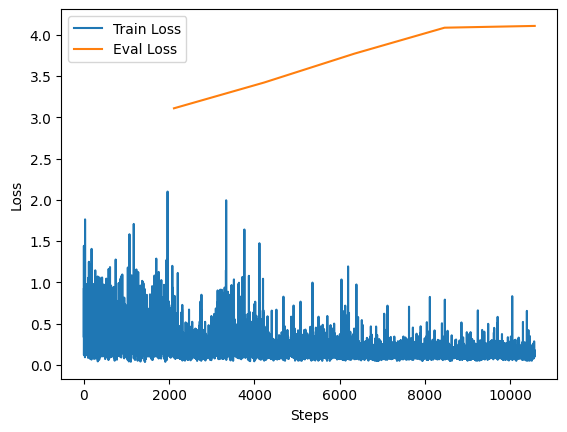

In [63]:

import matplotlib.pyplot as plt

# Initialize lists to hold training and evaluation losses and steps
train_losses = []
eval_losses = []
train_steps = []
eval_steps = []

# Populate the lists from the log history
for entry in trainer.state.log_history:
    if 'loss' in entry:
        train_losses.append(entry['loss'])
        train_steps.append(entry['step'])
    if 'eval_loss' in entry:
        eval_losses.append(entry['eval_loss'])
        eval_steps.append(entry['step'])

# Plot the losses
plt.plot(train_steps, train_losses, label='Train Loss')
plt.plot(eval_steps, eval_losses, label='Eval Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [64]:
adapter_model = f"agi123/{model_name}-optima_restore-ep5_bs1-adapters"
adapter_model

'agi123/DeepSeek-R1-Distill-Llama-8B-optima_restore-ep5_bs1-adapters'

In [65]:
model.push_to_hub(adapter_model, use_auth_token=True, max_shard_size="10GB", use_safetensors=True)

/usr/local/lib/python3.11/dist-packages/transformers/utils/hub.py:920: FutureWarning: The `use_auth_token` argument is deprecated and will be removed in v5 of Transformers. Please use `token` instead.
  warnings.warn(
loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--unsloth--DeepSeek-R1-Distill-Llama-8B/snapshots/7355e03ea25f9b9282d5ac3ec3a512106004b718/config.json
Model config LlamaConfig {
  "architectures": [
    "LlamaForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 128000,
  "eos_token_id": 128001,
  "head_dim": 128,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 14336,
  "max_position_embeddings": 131072,
  "mlp_bias": false,
  "model_type": "llama",
  "num_attention_heads": 32,
  "num_hidden_layers": 32,
  "num_key_value_heads": 8,
  "pad_token_id": 128004,
  "pretraining_tp": 1,
  "rms_norm_eps": 1e-05,
  "rope_scaling": {
    "factor": 8.0,
   

Uploading...:   0%|          | 0.00/83.9M [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/agi123/DeepSeek-R1-Distill-Llama-8B-optima_restore-ep5_bs1-adapters/commit/ce19a86c57b0b4959ed737943df747c2812e67fb', commit_message='Upload model', commit_description='', oid='ce19a86c57b0b4959ed737943df747c2812e67fb', pr_url=None, repo_url=RepoUrl('https://huggingface.co/agi123/DeepSeek-R1-Distill-Llama-8B-optima_restore-ep5_bs1-adapters', endpoint='https://huggingface.co', repo_type='model', repo_id='agi123/DeepSeek-R1-Distill-Llama-8B-optima_restore-ep5_bs1-adapters'), pr_revision=None, pr_num=None)

In [66]:
import wandb
import json
import os


artifact_name = 'sft_run_DeepSeek-R1-8B_ep5_bs1_00'
# Save training args
training_args_dict = trainer.args.to_dict()
os.makedirs(f"artifacts/{artifact_name}", exist_ok=True)

with open(f"artifacts/{artifact_name}/training_args.json", "w") as f:
    json.dump(training_args_dict, f, indent=4)


# Save evaluation results (assuming you used trainer.evaluate())
eval_results = trainer.evaluate()
with open(f"artifacts/{artifact_name}/eval_results.json", "w") as f:
    json.dump(eval_results, f, indent=4)


# (Optional) Save full run summary
summary_dict = dict(wandb.run.summary)
with open(f"artifacts/{artifact_name}/run_summary.json", "w") as f:
    json.dump(summary_dict, f, indent=4)


# Log it as a W&B artifact
artifact = wandb.Artifact(
    name=f"{artifact_name}_config_and_results",
    type="training-config",
    description="Arguments, evaluation results and wandb summary from SFTTrainer run with 5 epochs and bachsize 1",
)


artifact.add_dir(f"artifacts/{artifact_name}")
run.log_artifact(artifact)

run.finish()


***** Running Evaluation *****
  Num examples = 30
  Batch size = 1


wandb: Adding directory to artifact (./artifacts/sft_run_DeepSeek-R1-8B_ep5_bs1_00)... Done. 0.0s
wandb: WARNING Unable to render Widget, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
